In [ ]:

!pip install -q tensorflow-datasets


In [ ]:

import os


search_roots = ["/content", os.path.expanduser("~/.keras/datasets")]

for root in search_roots:
    if os.path.exists(root):
        print(f"\nSearching in: {root}")

        for current_path, dirs, files in os.walk(root):
            if "cats_and_dogs_filtered" in current_path:
                print(current_path)

            if (
                "cats" in dirs
                and "dogs" in dirs
            ):
                print("Possible image dataset:", current_path)


            dirs[:] = [
                d for d in dirs
                if d not in [".cache", "node_modules"]
            ]



Searching in: /content
/content/datasets/cats_and_dogs_filtered_extracted
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/validation
Possible image dataset: /content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/validation
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/validation/cats
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/validation/dogs
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/train
Possible image dataset: /content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/train
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/train/cats
/content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/train/dogs

Searching in: /root/.keras/datasets


In [ ]:

import os

train_dir = None
validation_dir = None

search_roots = ["/content", os.path.expanduser("~/.keras/datasets")]

for root in search_roots:
    if not os.path.isdir(root):
        continue

    for current_path, dirs, files in os.walk(root):

        if "cats" in dirs and "dogs" in dirs:
            parent = os.path.basename(current_path).lower()

            if parent == "train":
                candidate_validation = os.path.join(
                    os.path.dirname(current_path), "validation"
                )

                if os.path.isdir(candidate_validation):
                    if (
                        os.path.isdir(os.path.join(
                            candidate_validation, "cats"
                        ))
                        and os.path.isdir(os.path.join(
                            candidate_validation, "dogs"
                        ))
                    ):
                        train_dir = current_path
                        validation_dir = candidate_validation
                        break

        dirs[:] = [
            d for d in dirs
            if d not in [".cache", "node_modules"]
        ]

    if train_dir:
        break

if train_dir and validation_dir:
    print("Dataset found successfully!")
    print("Training directory:", train_dir)
    print("Validation directory:", validation_dir)
    print("Training classes:", os.listdir(train_dir))
    print("Validation classes:", os.listdir(validation_dir))
else:
    print("Could not locate the expected folders.")
    print("Run Step 1 and share the printed folder paths.")


Dataset found successfully!
Training directory: /content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/train
Validation directory: /content/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered/validation
Training classes: ['cats', 'dogs']
Validation classes: ['cats', 'dogs']


In [ ]:

import tensorflow as tf

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Images loaded successfully!")


Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Classes: ['cats', 'dogs']
Images loaded successfully!


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.5105 - loss: 0.7013 - val_accuracy: 0.5000 - val_loss: 0.6828
Epoch 2/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.5600 - loss: 0.6781 - val_accuracy: 0.6210 - val_loss: 0.6386
Epoch 3/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 153s 2s/step - accuracy: 0.6335 - loss: 0.6475 - val_accuracy: 0.6750 - val_loss: 0.6128
Epoch 4/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.6620 - loss: 0.6128 - val_accuracy: 0.6620 - val_loss: 0.6224
Epoch 5/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 167s 2s/step - accuracy: 0.6685 - loss: 0.6065 - val_accuracy: 0.6470 - val_loss: 0.6642
Epoch 6/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 104s 2s/step - accuracy: 0.6935 - loss: 0.5781 - val_accuracy: 0.7130 - val_loss: 0.5776
Epoch 7/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 135s 2s/step - accuracy: 0.7125 - loss: 0.5648 - val_accuracy: 0.6960 - val_loss: 0.5852
Epoch 8/20
63/63 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.7250 - loss: 0.5602 - val_accuracy: 0.6980 - val

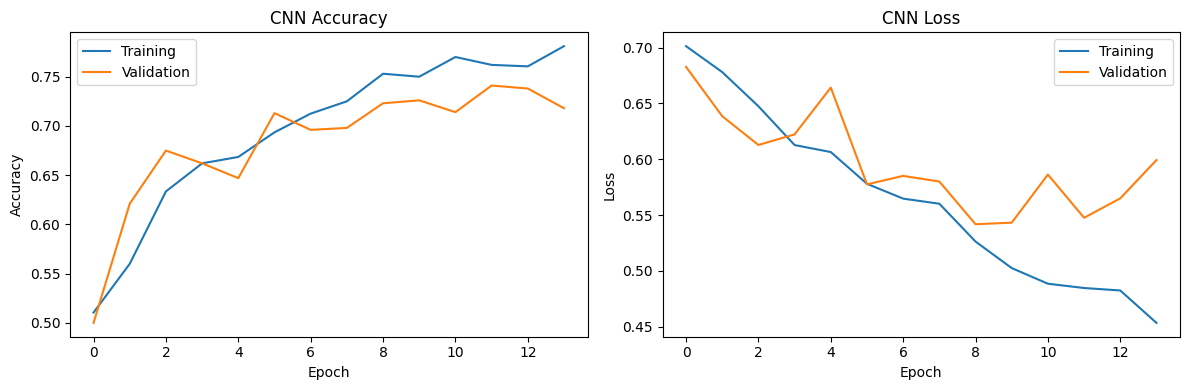

Model saved successfully!


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, Rescaling, RandomFlip, RandomRotation,
    Conv2D, MaxPooling2D, Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix


AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


cnn_model = Sequential([
    Input(shape=(128, 128, 3)),
    Rescaling(1.0 / 255),
    RandomFlip("horizontal"),
    RandomRotation(0.05),


    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),


    Conv2D(64, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),


    Conv2D(128, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])


cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()


early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)


loss, accuracy = cnn_model.evaluate(val_ds, verbose=1)

print(f"\nValidation loss: {loss:.4f}")
print(f"Validation accuracy: {accuracy * 100:.2f}%")


y_true, y_pred = [], []

for images, labels in val_ds:
    probabilities = cnn_model.predict(images, verbose=0).ravel()
    y_pred.extend((probabilities >= 0.5).astype(int))
    y_true.extend(labels.numpy().ravel().astype(int))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


cnn_model.save("/content/dog_cat_cnn.keras")
print("Model saved successfully!")
